# 0. Importe

test der Simulation aus THB_simu_aza035

nRTD training mit Parametern:
2bar
250 nml-min durch Reaktor
0 nml-min Matrix
150 °C
kein Katalysator im Reaktor (leeres Rohr)

Messwerte bei Messtelle Kapillare (Bypass der Anlage) aus FBA-E-18032025_300ml-min_Analytik_MS


Experiment und Referenz von AZA 035

In [ ]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate, correlation_lags
from pathlib import Path
import sys
import inspect


from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output_II import *
from AZA_THB_optimizer_II import Optimizer

if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 1) Importe Daten

In [9]:
# Auswertung Experiment
path_data_exp = np.load(r"Data files\t_n_out_n_RTD_n_trans_n_norm_cycle2_II.npy", allow_pickle=True)

# simulation path
path_opti_sys = np.load(r"Optimization Results\ 07-08-2026_aza035_.npy", allow_pickle=True).item()

# simulation path referenz
path_opti_sys_ref = np.load(r"Optimization Results\180_18.npy", allow_pickle=True).item()

In [10]:
# Dateien laden und extrahieren

Ar = 0

# aktuelles Experiment 
t_lin          = path_data_exp.item().get('t_lin')
ni_out_cycle   = path_data_exp.item().get('ni_out_cycle')
ni_trans_cycle = path_data_exp.item().get('ni_trans_cycle')
ni_RTD_cycle   = path_data_exp.item().get('ni_RTD_cycle')
C_balance      = path_data_exp.item().get('C_balance')
O_balance      = path_data_exp.item().get('O_balance')


# simulation 
t_lin_opti          = path_opti_sys.get('t_lin')
ni_trans_cycle_opti  = path_opti_sys.get('ni_trans_cycle')
ni_out_cycle_opti    = path_opti_sys.get('ni_out_cycle')
ni_RTD_cycle_opti    = path_opti_sys.get('ni_RTD_cycle')
n_dot_trans_int_opti = path_opti_sys.get('n_dot_trans_int')
n_dot_theo_int_opti  = path_opti_sys.get('n_dot_theo_int')
n_dot_i_int_opti     = path_opti_sys.get('n_dot_i_int')
theta_s_opti         = path_opti_sys.get('theta_s')
theta_x_opti         = path_opti_sys.get('theta_x')

# simulation Referenz
t_lin_ref          = path_opti_sys_ref.get('t_lin')
ni_trans_cycle_ref  = path_opti_sys_ref.get('ni_trans_cycle')
ni_out_cycle_ref    = path_opti_sys_ref.get('ni_out_cycle')
ni_RTD_cycle_ref    = path_opti_sys_ref.get('ni_RTD_cycle')
n_dot_trans_int_ref = path_opti_sys_ref.get('n_dot_trans_int')
n_dot_theo_int_ref  = path_opti_sys_ref.get('n_dot_theo_int')
n_dot_i_int_ref     = path_opti_sys_ref.get('n_dot_i_int')
theta_s_ref         = path_opti_sys_ref.get('theta_s')
theta_x_ref         = path_opti_sys_ref.get('theta_x')


# Berechnung

In [11]:
"""
===============================================================================
 Validierung der nRTD-Kernel aus dem Training
===============================================================================

WOZU DIESES SKRIPT
------------------
Das Trainingsskript liefert vier Verweilzeitdichten E1..E4 und dazu eigene
Guetezahlen ('validation_results'). Diese Guetezahlen pruefen aber nur, ob das
Netz die Daten reproduziert, an denen es gefittet wurde - das ist eine
Selbstkonsistenzpruefung, kein Test. Sie sind auch dann sehr gut (R2 > 0.999),
wenn sich Fehler in den einzelnen Stufen gegenseitig aufheben.

Dieses Skript prueft stattdessen JEDEN KERNEL EINZELN und ausserdem, ob die
zugrundeliegenden Messungen ueberhaupt zueinander passen.


DER TRICK: DIE KAPILLARE KUERZT SICH HERAUS
-------------------------------------------
Jede Messung entsteht durch die MS-Entnahme, enthaelt also immer die Kapillare
E4. Die vier Konfigurationen unterscheiden sich jeweils um genau einen Kernel:

    x_out cap    = Sprung (x) E4
    x_out inlet  = Sprung (x) E1 (x) E4
    x_out outlet = Sprung (x) E1 (x) E2 (x) E4
    x_out total  = Sprung (x) E1 (x) E2 (x) E3 (x) E4

Weil die Faltung kommutativ ist, folgt daraus:

    x_out inlet  = x_out cap    (x) E1        <- testet E1 allein
    x_out outlet = x_out inlet  (x) E2        <- testet E2 allein
    x_out total  = x_out outlet (x) E3        <- testet E3 allein

Das E4 auf beiden Seiten kuerzt sich. Damit laesst sich jeder Kernel einzeln
gegen echte Messdaten pruefen.

!!! HAEUFIGER FEHLER !!!
E4 darf in diesen Ketten NICHT nochmal auftauchen. 'x_out inlet (x) E2 (x) E3
(x) E4' ist falsch, weil E4 in x_out inlet schon steckt - das Ergebnis ist um
tau(E4) zu spaet und zu breit. Nur beim Weg vom DOSIERSPRUNG (x_in) aus, wo noch
gar keine Messung stattgefunden hat, gehoert E4 in die Kette.


AUFBAU (die vier Schritte laufen unabhaengig voneinander)
--------------------------------------------------------
  check_kernels()        Schritt 0: Integral = 1? gleiches dt? nichtnegativ?
                                    Wie verteilt sich die Dispersion?
  run_ladder()           Schritt 1: jeder Kernel einzeln + Ketten gegen Messdaten
  compare_to_experiment() Schritt 2: Kette gegen den echten Reaktorlauf
  moment_consistency()   Schritt 3: passen die Messungen ueberhaupt zueinander?


TYPISCHER AUFRUF
----------------
    from validate_training import run_ladder, compare_to_experiment, moment_consistency

    path_nRTDs = np.load(r"Data files\\Run_....npy", allow_pickle=True).item()
    exp        = np.load(r"Data files\\exp_data_evaluation_....npy", allow_pickle=True).item()

    results, curves, extra = run_ladder(path_nRTDs)                    # Schritte 0+1
    m, shift = compare_to_experiment(path_nRTDs, exp['t_lin'],
                                     exp['ni_out_cycle'], species=0)   # Schritt 2
    M = moment_consistency(path_nRTDs)                                 # Schritt 3


WIE MAN DIE ERGEBNISSE LIEST
----------------------------
  Schritt 0: Integrale sollten auf < 0.5 % bei 1 liegen. Der wichtigste Wert ist
             die Verteilung der Dispersion: sitzt der Grossteil im Reaktor (E2),
             ist das physikalisch plausibel. Sitzt er in der Kapillare (E4), war
             die Kapillarcharakterisierung vermutlich nicht im echten Signalweg.

  Schritt 1: Jede Zeile sollte unter ~2 % relativem Flanken-RMSE liegen. Wichtiger
             als die Zahl ist der Vergleich der FLANKENBREITEN: sind einzelne
             Stufen zu breit und andere gegenlaeufig zu schmal, waehrend die
             Gesamtkette passt, hat das Training kompensierende Fehler gelernt.
             Die Gesamtuebertragung stimmt dann, die Aufteilung aber nicht - und
             genau die Aufteilung braucht das Reaktormodell, weil es die Kinetik
             zwischen E1 und E2 setzt.

  Schritt 2: Der Tracer ist inert, die Kette muss die gemessene Ar-Antwort des
             Reaktorlaufs also ohne jede Kinetik treffen. Der ausgegebene
             Zeitversatz ist Buchhaltung (ungerollte Messdatei), keine Physik.

  Schritt 3: Verzugszeiten und Varianzen addieren sich entlang der Kette. Jede
             Stufe MUSS positiv beitragen - eine Faltung mit einem
             nichtnegativen Kernel kann ein Signal niemals schaerfen. Negative
             Beitraege bedeuten, dass zwei Messungen nicht denselben Signalweg
             hatten. Das kann kein Training reparieren.


KONVENTIONEN IN DEN DATEIEN
---------------------------
  * Kernelindizes:  Es[0] = Einlassleitung (hier E1)
                    Es[1] = Reaktor         (hier E2)
                    Es[2] = Auslassleitung  (hier E3)
                    Es[3] = Kapillare       (hier E4)
    Vorsicht: die Datei zaehlt ab 0, dieses Skript beschriftet ab 1.
    Massgeblich ist immer path_nRTDs['kernel_map'].

  * Laufmuster in x_out/x_in: 20 Laeufe = 5 Wiederholungen x 4 Typen.
        Index 4i+0 = Ar auf,  4i+1 = He ab,  4i+2 = Ar ab,  4i+3 = He auf
    build_cycle() nimmt per Default (0, 2), also die Argon-Halbperioden.

  * Jeder x_out-Lauf ist eine HALBperiode (0..120 s, dt = 0.25 s). build_cycle()
    setzt Ar-Auf und Ar-Ab zu einer geschlossenen 240-s-Periode zusammen.
===============================================================================
"""
import numpy as np
import matplotlib.pyplot as plt

# ============================== KONFIGURATION ================================
CYCLE_TIME = 480.0        # Periodendauer in s (BU + BT)
BU_FRACTION = 0.25         # Anteil der BU-Phase an der Periode

FLANK_HALF_WIDTH = 20.0   # halbe Fensterbreite der Flankenmaske in s.
                          # None -> gradientenbasierte Maske (siehe flank_mask)
DYN_THRESH = 0.02         # nur fuer die gradientenbasierte Maske relevant

PLATEAU_KEEP = 0.5        # Anteil jeder Halbperiode, ueber den das stationaere
                          # Plateau gemittelt wird (0.5 = mittlere Haelfte)

KERNEL_NAME = {0: 'E1 Einlassleitung', 1: 'E2 Reaktor',
               2: 'E3 Auslassleitung', 3: 'E4 Kapillare'}
# =============================================================================


# =============================================================================
#  SCHRITT 0   Kernelpruefung
# =============================================================================
def check_kernels(ts, Es, names=KERNEL_NAME, tol=1e-3, renormalize=True, verbose=True):
    """Prueft die Kernel und gibt sie auf Integral 1 normiert zurueck.

    Geprueft wird dreierlei:

    1. INTEGRAL = 1. Eine Verweilzeitdichte ist eine Wahrscheinlichkeitsdichte;
       ihr Integral muss 1 sein. Ist es das nicht, skaliert jede Faltung die
       Amplitude mit diesem Faktor - und ueber eine vierstufige Kette
       MULTIPLIZIEREN sich die Abweichungen. 4 x 0.3 % sind schon ueber 1 %.
       Das Trainingsergebnis liegt typisch bei 0.2...0.6 % daneben, deshalb wird
       hier immer normiert.

    2. GLEICHES dt. Alle Kernel muessen auf demselben Zeitraster liegen, sonst
       ist np.convolve(...) * dt schlicht falsch (der Faktor dt waere pro Kernel
       verschieden). Wird als Fehler geworfen, nicht nur gewarnt.

    3. NICHTNEGATIVITAET. Ein Kernel mit negativen Anteilen ist physikalisch
       sinnlos (negative Wahrscheinlichkeit). Kleine negative Ausschlaege sind
       Fitartefakte und meist unkritisch; grosse deuten darauf hin, dass das Netz
       versucht hat, eine unmoegliche Messkombination auszugleichen.

    Zusaetzlich ausgegeben werden die Momente:
        tau   = Erwartungswert  -> mittlere Verweilzeit, "wie spaet"
        sigma = Standardabw.    -> Dispersion, "wie breit"
    Beide addieren sich entlang der Kette (sigma allerdings quadratisch, deshalb
    wird die Varianz sigma^2 aufsummiert). Die Aufteilung der Varianz auf die
    Stufen ist die diagnostisch wertvollste Zahl im ganzen Schritt.

    Args:
        ts, Es: Listen der Zeitachsen und Kernel (aus path_nRTDs['ts'/'Es'])
        tol: Toleranz fuer die Warnungen
        renormalize: False gibt die Rohkernel zurueck (nur fuer Diagnosen)
        verbose: False unterdrueckt die Ausgabe (fuer wiederholte Aufrufe)

    Returns:
        (ts, Es_normiert, dt)
    """
    ts = [np.asarray(t, float) for t in ts]
    Es = [np.asarray(E, float) for E in Es]
    out, dts = [], []

    if verbose:
        print('=' * 78)
        print('SCHRITT 0  Kernelpruefung')
        print('=' * 78)
        print(f'{"Kernel":22s} {"dt":>7s} {"t_end":>8s} {"Integral":>10s} {"tau":>8s} '
              f'{"sigma":>7s} {"min(E)":>11s}')

    for i, (t, E) in enumerate(zip(ts, Es)):
        # --- gleichmaessiges Raster? (Voraussetzung fuer np.convolve * dt) ---
        d = np.diff(t)
        if not np.allclose(d, d[0], rtol=1e-9, atol=1e-12):
            raise ValueError(f'Kernel {i}: Zeitachse ist nicht gleichmaessig.')
        dts.append(d[0])

        # --- Normierung auf Integral 1 ---
        integral = np.trapezoid(E, t)
        En = E / integral if renormalize else E

        # --- Momente: tau = 1. Moment, sigma = Wurzel des 2. Zentralmoments ---
        tau = np.trapezoid(t * En, t)
        sig = np.sqrt(np.trapezoid((t - tau) ** 2 * En, t))

        flag = ''
        if abs(integral - 1) > tol:
            flag += f'  <- Integral weicht um {100 * (integral - 1):+.2f} % ab'
        if E.min() < -tol * E.max():
            flag += f'  <- negative Anteile ({100 * E.min() / E.max():.2f} % von max)'

        if verbose:
            print(f'{names.get(i, f"E{i}"):22s} {d[0]:7.3f} {t[-1]:8.2f} {integral:10.5f} '
                  f'{tau:7.2f}s {sig:6.2f}s {E.min():11.2e}{flag}')
        out.append(En)

    # --- alle Kernel auf demselben Raster? ---
    if not np.allclose(dts, dts[0], rtol=1e-9, atol=1e-12):
        raise ValueError(f'Kernel haben verschiedene dt: {dts}. '
                         f'Die Faltung waere dann falsch skaliert.')

    if verbose:
        # Momente der Gesamtkette: tau addiert sich, sigma^2 addiert sich
        taus = [np.trapezoid(t * E, t) for t, E in zip(ts, out)]
        variances = [np.trapezoid((t - tau) ** 2 * E, t)
                     for t, E, tau in zip(ts, out, taus)]
        var_sum = sum(variances)

        print(f'\n  Summe: tau = {sum(taus):.2f} s,  sigma = {np.sqrt(var_sum):.2f} s '
              f'(Varianzen sind additiv)')
        print('  Dispersionsanteile: ' + ', '.join(
            f'{names.get(i, f"E{i}").split()[0]} {100 * v / var_sum:.1f} %'
            for i, v in enumerate(variances)))
        print('  -> Erwartung: das Festbett (E2) sollte dominieren. Dominiert die')
        print('     Kapillare (E4), war deren Charakterisierung vermutlich nicht im')
        print('     echten Signalweg (z.B. ueber den Anlagenbypass gemessen).')
        print()

    return ts, out, float(dts[0])


# =============================================================================
#  KERNELKETTEN
# =============================================================================
def chain_kernels(Es, idx, dt):
    """Faltet mehrere Kernel zu einem Gesamtkernel zusammen.

    Beispiel: chain_kernels(Es, [1, 2], dt) liefert E2 (x) E3.

    Statt ein Signal nacheinander mit mehreren Kernen zu falten, faltet man
    besser erst die Kerne miteinander und dann das Signal einmal. Ergebnis
    identisch (Assoziativitaet), aber nur eine Signalfaltung und damit nur ein
    einziger Randeffekt statt mehrerer.

    Der Faktor dt kommt daher, dass np.convolve eine Summe bildet, die Faltung
    aber ein Integral ist: Integral f(t') g(t-t') dt' ~ Summe * dt.

    Args:
        Es: Liste der (bereits normierten) Kernel
        idx: Indizes der zu verkettenden Kernel, z.B. [0, 1, 2]
        dt: Zeitschritt

    Returns:
        (t_tot, E_tot) - E_tot ist auf Integral 1 normiert
    """
    E_tot = np.asarray(Es[idx[0]], float)
    for j in idx[1:]:
        E_tot = np.convolve(E_tot, Es[j]) * dt

    t_tot = np.arange(E_tot.size) * dt
    return t_tot, E_tot / np.trapezoid(E_tot, t_tot)


# =============================================================================
#  SIGNALE AUFBEREITEN
# =============================================================================
def build_cycle(x_out, period_indices=(0, 2), normalize=True, dt=0.25, min_span=0.05):
    """Setzt aus den gemessenen Halbperioden eine geschlossene Vollperiode zusammen.

    Die nRTD-Datei speichert 20 Laeufe = 5 Wiederholungen x 4 Typen:
        Index 4i+0 = Ar auf,  4i+1 = He ab,  4i+2 = Ar ab,  4i+3 = He auf
    Jeder Lauf ist eine Halbperiode von 0..120 s.

    Diese Funktion mittelt ueber die 5 Wiederholungen (senkt das Rauschen) und
    haengt Ar-Auf und Ar-Ab zu einer 240-s-Periode aneinander. Der letzte Punkt
    wird gleich dem ersten gesetzt, damit die Periode geschlossen ist - das
    braucht convolve_periodic().
    (Geprueft: die Nahtstellen springen um < 0.15 % des Hubs, die Halbperioden
    passen also sauber aneinander.)

    WARUM NORMIEREN (normalize=True ist Default und sollte es bleiben):
    Die vier Konfigurationen haben unterschiedliche Verduennung - im alten Lauf
    lag das Ar-Plateau bei 0.159 vor dem Reaktor, aber bei 0.049 danach, weil
    Matrixgas zudosiert wurde. Ohne Normierung vergleicht man Amplituden statt
    Formen, und jeder Test zwischen den Gruppen scheitert aus rein
    stoechiometrischen Gruenden (R2 um -36 gemessen). Die Faltung ist linear,
    die Normierung also unbedenklich: (a*x + b) (x) E = a*(x (x) E) + b.

    Args:
        x_out: Array (20, 1, 481) aus path_nRTDs['x_out ...']
        period_indices: (Index Aufsprung, Index Absprung) im 4er-Muster.
                        (0, 2) = Argon (Default), (3, 1) = Helium.
                        Helium waere ein unabhaengiger Kreuztest (anderer
                        Diffusionskoeffizient, gleicher Weg) - ABER: an den
                        Positionen outlet/total aendert sich der He-Molenbruch
                        nur um wenige Promille, weil He dort Traegergas ist. Der
                        Kreuztest ist deshalb nur fuer cap und inlet aussagekraeftig;
                        min_span warnt automatisch, wenn der Hub zu klein ist.
        normalize: auf die Plateaus normieren (BT -> 0, BU -> 1)
        dt: Zeitschritt der Messung
        min_span: Mindesthub relativ zum Signalniveau; darunter wird gewarnt.
                  None schaltet die Warnung ab.

    Returns:
        Array der Laenge 961 (240 s bei dt = 0.25 s)
    """
    n = x_out.shape[0] // 4
    i_up, i_dn = period_indices

    bu = np.mean([x_out[4 * i + i_up, 0] for i in range(n)], axis=0)   # BU-Halbperiode
    bt = np.mean([x_out[4 * i + i_dn, 0] for i in range(n)], axis=0)   # BT-Halbperiode

    cycle = np.hstack((bu, bt[1:]))     # bt[1:], weil bu[-1] und bt[0] derselbe Punkt sind
    cycle[-1] = cycle[0]                # Periode schliessen

    # Hubkontrolle: ist der Sprung ueberhaupt gross genug, um auswertbar zu sein?
    # Beim Heliumkreuztest ist das oft NICHT der Fall - He ist Traegergas, sein
    # Molenbruch aendert sich hinter dem Reaktor teils nur um ein paar Promille.
    # Nach der Normierung sieht die Kurve trotzdem wie ein sauberer Sprung aus,
    # ist aber fast reines Rauschen. Deshalb hier warnen statt stillschweigend
    # unbrauchbare Kennzahlen zu liefern.
    span = abs(cycle.max() - cycle.min())
    level = max(abs(cycle.max()), abs(cycle.min()))
    if min_span is not None and level > 0 and span / level < min_span:
        print(f'  WARNUNG build_cycle: Hub betraegt nur {100 * span / level:.2f} % '
              f'des Signalniveaus (period_indices={period_indices}). '
              f'Kennzahlen aus diesem Signal sind nicht belastbar.')

    if normalize:
        t_cyc = np.arange(cycle.size) * dt
        y_bu, y_bt = plateau_levels(cycle, t_cyc)
        cycle = (cycle - y_bt) / (y_bu - y_bt)

    return cycle


def plateau_levels(y, t, keep=PLATEAU_KEEP):
    """Ermittelt die stationaeren Niveaus der BU- und der BT-Phase.

    ACHTUNG, hier steckt eine Falle: Gemittelt wird ueber den MITTLEREN Teil
    jeder Halbperiode, NICHT in einem Fenster kurz vor der naechsten Flanke.

    Warum das wichtig ist: bei ~10 s Flankenbreite beginnt das Signal schon rund
    10 s vor t50 zu kippen. Ein Fenster unmittelbar vor der Flanke erwischt also
    deren Anfang, der Referenzwert wird zu niedrig, und das Plateau landet nach
    der Normierung bei 1.02 statt 1.00. Im Residuum sieht man das als konstanten
    Versatz auf beiden Plateaus - ein Niveaufehler, der faelschlich wie eine
    Modellabweichung aussieht.

    Die Flankenpositionen werden ueber den groessten bzw. kleinsten Gradienten
    gefunden. Alle Indexrechnungen sind zyklisch (modulo), weil die Periode
    geschlossen ist und die BT-Phase ueber das Arrayende laeuft.

    Args:
        keep: Anteil jeder Halbperiode, der gemittelt wird. 0.5 = mittlere
              Haelfte, also je 25 % Sicherheitsabstand zu beiden Flanken.

    Returns:
        (y_bu, y_bt) - Niveau der BU- und der BT-Phase
    """
    g = np.gradient(y, t)
    i_rise, i_fall = int(np.argmax(g)), int(np.argmin(g))
    n = y.size

    def middle_mean(i_start, i_end):
        """Mittelwert ueber den mittleren Anteil des zyklischen Intervalls."""
        length = (i_end - i_start) % n
        if length == 0:
            length = n
        skip = int(round(length * (1 - keep) / 2))       # Sicherheitsabstand zu den Flanken
        idx = (i_start + np.arange(skip, length - skip)) % n
        return float(np.mean(y[idx]))

    y_bu = middle_mean(i_rise, i_fall)      # Intervall Anstieg -> Abfall = BU-Phase
    y_bt = middle_mean(i_fall, i_rise)      # Intervall Abfall -> Anstieg = BT-Phase
    return y_bu, y_bt


def normalize_steady_state(y, t, keep=PLATEAU_KEEP):
    """Normiert eine periodische Kurve auf ihre stationaeren Plateaus.

    BT-Plateau -> 0, BU-Plateau -> 1. Damit sind Kurven mit unterschiedlicher
    Verduennung oder Absolutkalibrierung direkt in der Form vergleichbar.

    Vorzuziehen gegenueber y / y.max(): das Maximum ist ein EINZELNER Punkt und
    liegt bei ueberschwingenden Kurven 1...3 % ueber dem Plateau. Weil der
    Ueberschwinger kurvenabhaengig ist, erzeugt die max-Normierung eine
    scheinbare Amplitudenabweichung, die es gar nicht gibt.
    """
    y_bu, y_bt = plateau_levels(y, t, keep)
    return (y - y_bt) / (y_bu - y_bt)


def build_dosing_step(path_nRTDs, dt, cycle_time=CYCLE_TIME, bu_fraction=BU_FRACTION):
    """Rekonstruiert den Dosiersprung (das Ventilsignal) als geschlossene Periode.

    x_in in der Datei deckt nur die ersten 10..20 s ab, also gerade den Sprung
    selbst. Der Sprungzeitpunkt wird daraus bestimmt und auf die volle Periode
    fortgeschrieben.

    Geprueft an den Rohdaten: x_in ist in allen vier Konfigurationen, beiden
    Sprungrichtungen und allen Wiederholungen ein EXAKTES Rechteck (Abweichung
    0.00 %). Der Sprung liegt nicht bei t = 0, sondern nach einer kurzen
    Vorlaufzeit - die gehoert zur Zeitbasis, auf der die Kernel identifiziert
    wurden, und muss deshalb uebernommen werden.

    Returns:
        Array der Laenge int(cycle_time/dt)+1, Werte 0 (BT) und 1 (BU)
    """
    x = path_nRTDs['x_in total'][0, 0]
    t_in = np.asarray(path_nRTDs['t_in total'])[0]

    i_step = int(np.argmax(np.abs(np.diff(x)))) + 1        # groesster Sprung im Signal
    lead_in = float(t_in[i_step]) if i_step < t_in.size else i_step * dt

    n = int(round(cycle_time / dt)) + 1
    step = np.zeros(n)
    step[int(round(lead_in / dt)):
         int(round((lead_in + bu_fraction * cycle_time) / dt))] = 1.0
    step[-1] = step[0]                                      # Periode schliessen
    return step


def convolve_periodic(one_period, kernel, dt):
    """Faltet ein PERIODISCHES Signal - exakt, ohne Randeffekt.

    Das Problem: eine gewoehnliche Faltung braucht die Vorgeschichte des Signals.
    Bei einem periodischen Prozess ist diese Vorgeschichte die vorhergehende
    Periode. Paddet man stattdessen mit dem konstanten Anfangswert (der
    naheliegende Reflex), unterstellt man, das System haette vorher ewig
    stillgestanden - falsch, sobald der Kernel laenger ist als die Zeit, die seit
    der letzten Flanke vergangen ist.

    Die Loesung hier: das Signal so oft kacheln, dass der Kernel vollstaendig
    hineinpasst, einmal durchfalten und den MITTLEREN (eingeschwungenen) Zyklus
    herausschneiden. Dessen Vorgeschichte ist dann die echte Periode.

    Die Kachelung nutzt sig[:, :-1], weil der letzte Punkt jeder Periode mit dem
    ersten der naechsten identisch ist - sonst waere er doppelt.

    Args:
        one_period: 1D- oder 2D-Array einer GESCHLOSSENEN Periode
                    (erster Punkt = letzter Punkt)
        kernel: auf Integral 1 normierter Kernel
        dt: Zeitschritt (identisch fuer Signal und Kernel)

    Returns:
        gefaltetes Signal, gleiche Form wie one_period
    """
    sig = np.atleast_2d(np.asarray(one_period, float))
    n = sig.shape[1]

    n_rep = int(np.ceil(kernel.size / (n - 1))) + 4         # +4 = Sicherheitsreserve
    tiled = np.hstack([sig[:, :-1]] * (n_rep - 1) + [sig])
    mid = (n_rep // 2) * (n - 1)                            # Start des mittleren Zyklus

    out = np.array([(np.convolve(tiled[i], kernel) * dt)[mid:mid + n]
                    for i in range(sig.shape[0])])
    return out.reshape(np.shape(one_period))


# =============================================================================
#  KENNZAHLEN
# =============================================================================
def flank_mask(y, t, half_width=FLANK_HALF_WIDTH, thresh=DYN_THRESH):
    """Boolesche Maske ueber BEIDE Flanken der Periode.

    Warum ueberhaupt maskieren: auf den Plateaus ist das Signal konstant. Dort
    ist R2 unbrauchbar (der Nenner, die Varianz der Referenz, geht gegen 0) und
    RMSE misst nur Messrauschen. Die gesamte Information ueber die Guete der
    Kernel steckt in den Flanken.

    Zwei Varianten:
      half_width = <Sekunden>  feste Fenster um die beiden Flankenmitten.
                               Reproduzierbar, unabhaengig vom Rauschen, die
                               Punktzahl ist immer gleich. Fuer Kennzahlen in der
                               Arbeit die bessere Wahl - Default.
      half_width = None        gradientenbasiert: alle Punkte mit nennenswerter
                               Aenderung. Passt sich der Flankenbreite an, ist
                               aber rauschabhaengig und liefert je nach Kurve
                               unterschiedlich viele Punkte.

    WICHTIG: Die Maske wird immer aus der REFERENZ berechnet, nie aus der
    Testkurve - sonst wird fuer jedes Modell ein anderer Punktesatz verglichen
    und die Zahlen sind untereinander nicht mehr vergleichbar. metrics() macht
    das automatisch richtig.
    """
    g = np.gradient(y, t)

    if half_width is None:
        return np.abs(g) > thresh * np.abs(g).max()

    w = int(round(half_width / (t[1] - t[0])))
    m = np.zeros(y.size, dtype=bool)
    for i in (int(np.argmax(g)), int(np.argmin(g))):        # Anstieg und Abfall
        m[np.arange(i - w, i + w + 1) % y.size] = True      # zyklisch
    return m


dynamic_mask = flank_mask          # alter Name, aus Kompatibilitaetsgruenden


def metrics(y_ref, y_test, t, thresh=DYN_THRESH, half_width=FLANK_HALF_WIDTH):
    """R2 und RMSE - massgeblich sind die Werte AUF DEN FLANKEN.

    Die Gesamtwerte ('R2', 'RMSE') werden mitgefuehrt, sind aber nicht
    aussagekraeftig: sie werden von den langen konstanten Plateaus dominiert und
    sehen fast immer sehr gut aus, auch wenn die Flanken deutlich danebenliegen.

    Returns (dict):
        R2, RMSE            ueber die ganze Periode (nur informativ)
        R2_dyn, RMSE_dyn    auf den Flanken - DAS sind die Bewertungszahlen
        RMSE_dyn_rel        Flanken-RMSE relativ zum Hub der Referenz, also
                            direkt als Prozentzahl lesbar
        mask                die verwendete Maske (fuer Plots)
        n_dyn               Anzahl bewerteter Punkte
    """
    m = flank_mask(y_ref, t, half_width, thresh)            # Maske aus der REFERENZ
    span = y_ref.max() - y_ref.min()

    def r2(a, b):
        return 1 - np.sum((a - b) ** 2) / np.sum((a - a.mean()) ** 2)

    rmse_dyn = np.sqrt(np.mean((y_ref[m] - y_test[m]) ** 2))

    return {
        'R2':           r2(y_ref, y_test),
        'R2_dyn':       r2(y_ref[m], y_test[m]),
        'RMSE':         np.sqrt(np.mean((y_ref - y_test) ** 2)),
        'RMSE_dyn':     rmse_dyn,
        'RMSE_dyn_rel': rmse_dyn / span,
        'mask':         m,
        'n_dyn':        int(m.sum()),
    }


def flank_stats(t, y, rising=True, half=30.0):
    """t50 und 10-90-Breite EINER Flanke.

    Diese beiden Zahlen trennen die zwei Fehlerarten sauber voneinander:
        t50    - wann die Flanke liegt   -> Fehler in tau (Verzugszeit)
        Breite - wie steil sie ist       -> Fehler in sigma (Dispersion)

    Das ist diagnostisch viel nuetzlicher als R2 allein: ein zu breites Modell
    und ein zeitversetztes Modell koennen dasselbe R2 haben, brauchen aber voellig
    verschiedene Korrekturen.

    Die Flanke wird ueber den Extremwert des Gradienten lokalisiert, dann im
    Fenster +-half normiert und die Durchgaenge durch 10 %, 50 % und 90 %
    interpoliert. Indexrechnung zyklisch, damit auch Flanken nahe am Arrayrand
    funktionieren.

    Returns:
        (t50, Breite_10_90) in s; NaN, falls im Fenster kein Durchgang liegt
    """
    g = np.gradient(y, t)
    i = int(np.argmax(g)) if rising else int(np.argmin(g))

    w = int(round(half / (t[1] - t[0])))
    sl = np.arange(i - w, i + w) % y.size
    tt, z = t[sl], y[sl]

    z = (z - z.min()) / (z.max() - z.min())
    if not rising:
        z = 1 - z                                # Abfall auf "steigend" umdrehen

    def cross(f):
        cr = np.where((z[:-1] <= f) & (z[1:] > f))[0]
        if cr.size == 0:
            return np.nan
        j = int(cr[0])
        return np.interp(f, [z[j], z[j + 1]], [tt[j], tt[j + 1]])

    return cross(0.5), cross(0.9) - cross(0.1)


# =============================================================================
#  SCHRITT 1   Kernelweise Validierung
# =============================================================================
def run_ladder(path_nRTDs, cycle_time=CYCLE_TIME, plot=True,
               thresh=DYN_THRESH, zoom=20.0, period_indices=(0, 2)):
    """Prueft jeden Kernel einzeln und die Ketten gegen Messdaten.

    Ruft intern check_kernels() auf (Schritt 0) und arbeitet dann die Testleiter
    aus dem Modulkopf ab.

    WORAUF ZU ACHTEN IST:
    Nicht nur auf R2 und RMSE schauen, sondern vor allem auf die
    FLANKENBREITEN in der Tabelle darunter. Das Fehlerbild
        Stufe A zu breit  +  Stufe B gegenlaeufig zu schmal  +  Kette passt
    bedeutet, dass das Training kompensierende Fehler gelernt hat: die
    Gesamtuebertragung stimmt, die Aufteilung auf die Stufen nicht. Fuer eine
    reine Tracer-Validierung ist das folgenlos, fuer die Kinetik nicht - das
    Reaktormodell setzt die Reaktion zwischen E1 und E2, die Aufteilung ist also
    genau die Groesse, auf die es ankommt.

    Args:
        period_indices: (0, 2) = Argon (Default), (3, 1) = Helium.
                        Der Heliumlauf ist ein unabhaengiger Kreuztest: anderer
                        Diffusionskoeffizient, aber derselbe Transportweg.
        zoom: halbe Breite der Zoomfenster in den Plots, s

    Returns:
        (results, curves, (t_cyc, sig, Es, dt))
        results: dict {Testname: metrics-dict}
        curves:  dict {Testname: (Referenz, Vorhersage, Quelle, Indizes, Ziel)}
    """
    ts, Es, dt = check_kernels(path_nRTDs['ts'], path_nRTDs['Es'])

    # Alle vier Messkonfigurationen als geschlossene, normierte Perioden
    sig = {tag: build_cycle(path_nRTDs[f'x_out {tag}'], period_indices, dt=dt)
           for tag in ['cap', 'inlet', 'outlet', 'total']}
    t_cyc = np.arange(sig['cap'].size) * dt

    # Die Testleiter. Aufbau je Eintrag:
    #   (Beschriftung, Quellmessung, Kernelindizes, Zielmessung)
    # Erinnerung: E4 (Index 3) taucht hier NIE auf - es steckt in beiden
    # Messungen und kuerzt sich heraus.
    tests = [
        ('E1 allein:  cap    (x) E1        -> inlet',    'cap',    [0],       'inlet'),
        ('E2 allein:  inlet  (x) E2        -> outlet',   'inlet',  [1],       'outlet'),
        ('E3 allein:  outlet (x) E3        -> total',    'outlet', [2],       'total'),
        ('Kette:      inlet  (x) E2(x)E3   -> total',    'inlet',  [1, 2],    'total'),
        ('Kette:      cap    (x) E1(x)E2(x)E3 -> total', 'cap',    [0, 1, 2], 'total'),
    ]

    print('=' * 78)
    print('SCHRITT 1  Kernelweise Validierung gegen Messdaten')
    print('=' * 78)
    print('(Kennzahlen nur auf den Flanken, Signale auf die Plateaus normiert)')
    print(f'{"Test":44s} {"R2_fl":>9s} {"RMSE_fl":>10s} {"rel":>7s}')

    results, curves = {}, {}
    for name, src, idx, tgt in tests:
        _, E_tot = chain_kernels(Es, idx, dt)               # Kernel verketten
        pred = convolve_periodic(sig[src], E_tot, dt)       # Quellsignal falten
        m = metrics(sig[tgt], pred, t_cyc, thresh)          # gegen Zielmessung
        results[name] = m
        curves[name] = (sig[tgt], pred, src, idx, tgt)
        print(f'{name:44s} {m["R2_dyn"]:8.5f} {m["RMSE_dyn"]:10.3e} '
              f'{m["RMSE_dyn_rel"] * 100:6.2f} %')

    # --- Absolutweg vom Dosiersprung ---
    # Einziger Test, in dem E4 vorkommt: der Dosiersprung ist keine Messung,
    # enthaelt also noch keine Kapillare. Prueft die Kette als Ganzes inklusive
    # der absoluten Zeitbasis.
    print()
    print('  Absolutweg vom Dosiersprung (nur hier gehoert E4 dazu):')
    x_in = build_dosing_step(path_nRTDs, dt, cycle_time)
    _, E_all = chain_kernels(Es, [0, 1, 2, 3], dt)
    pred = convolve_periodic(x_in, E_all, dt)
    m = metrics(sig['total'], pred, t_cyc, thresh)

    key = 'Dosiersprung (x) E1(x)E2(x)E3(x)E4 -> total'
    results[key] = m
    curves[key] = (sig['total'], pred, 'x_in', [0, 1, 2, 3], 'total')
    print(f'  {key:42s} {m["R2_dyn"]:8.5f} {m["RMSE_dyn"]:10.3e} '
          f'{m["RMSE_dyn_rel"] * 100:6.2f} %')

    # --- Flankenkennzahlen: zeigen, WO die Abweichung sitzt ---
    # t50 daneben     -> Verzugszeit tau des Kernels stimmt nicht
    # Breite daneben  -> Dispersion sigma stimmt nicht
    # Plateaus != 1/0 -> Normierung hat nicht gegriffen (sollte nie vorkommen)
    print()
    print('  Flankenkennzahlen (t50 / 10-90-Breite):')
    print(f'{"":44s} {"Anstieg":>18s} {"Abfall":>18s}')
    for name, (ref, pred, *_rest) in curves.items():
        for lbl, y in [('Messung', ref), ('Modell ', pred)]:
            a, b = flank_stats(t_cyc, y, True)
            c, e = flank_stats(t_cyc, y, False)
            bu, bt = plateau_levels(y, t_cyc)
            print(f'   {name[:40]:40s} {lbl} {a:7.2f}s/{b:5.2f}s {c:8.2f}s/{e:5.2f}s'
                  f'   Plateaus {bu:.4f}/{bt:.4f}')
        print()

    if plot:
        _plot_ladder(curves, results, t_cyc, zoom)

    return results, curves, (t_cyc, sig, Es, dt)


def _plot_ladder(curves, results, t_cyc, zoom):
    """Vier Panels je Test: Gesamtperiode, Anstieg, Abfall, Residuum.

    Die Zoomfenster sind der Kern der Abbildung - in der Gesamtansicht liegen
    alle Kurven scheinbar perfekt uebereinander, die Unterschiede in der
    Flankenbreite sieht man erst im Zoom. Im Residuum sind beide Zoombereiche
    eingefaerbt, damit erkennbar ist, welcher Teil des Residuums wo herkommt.
    """
    n = len(curves)
    fig, axes = plt.subplots(n, 4, figsize=(19, 3.0 * n),
                             gridspec_kw={'width_ratios': [2, 1, 1, 1.4]})
    axes = np.atleast_2d(axes)

    for ax_row, (name, (ref, pred, src, idx, tgt)) in zip(axes, curves.items()):
        msk = results[name]['mask']
        g = np.gradient(ref, t_cyc)
        t_rise, t_fall = t_cyc[int(np.argmax(g))], t_cyc[int(np.argmin(g))]

        # Panel 1: Gesamtperiode, bewerteter Bereich gruen hinterlegt
        ax = ax_row[0]
        ax.plot(t_cyc, ref, 'k--', lw=1.2, label=f'Messung {tgt}')
        ax.plot(t_cyc, pred, color='tab:orange', lw=1.2, label='gefaltet')
        ax.fill_between(t_cyc, -0.05, 1.05, where=msk, color='tab:green', alpha=0.06)
        ax.axhline(0, color='gray', lw=0.5)      # Sollwert BT-Plateau
        ax.axhline(1, color='gray', lw=0.5)      # Sollwert BU-Plateau
        ax.set_title(name, fontsize=8); ax.legend(fontsize=7)
        ax.set_xlabel('t / s'); ax.set_ylabel('normiert / 1')

        # Panel 2 und 3: Zoom auf beide Flanken, mit 10/50/90-Linien
        for ax, t_c, ttl in [(ax_row[1], t_rise, 'Anstieg'),
                             (ax_row[2], t_fall, 'Abfall')]:
            ax.plot(t_cyc, ref, 'k--', lw=1.2, marker='.', ms=2, label='Messung')
            ax.plot(t_cyc, pred, color='tab:orange', lw=1.2, marker='.', ms=2,
                    label='gefaltet')
            ax.set_xlim(t_c - zoom, t_c + zoom); ax.set_ylim(-0.05, 1.05)
            for lvl in (0.1, 0.5, 0.9):
                ax.axhline(lvl, color='gray', lw=0.5, ls=':')
            ax.set_title(ttl, fontsize=8); ax.legend(fontsize=7)
            ax.set_xlabel('t / s')

        # Panel 4: Residuum. Flach auf den Plateaus = Normierung sitzt.
        ax = ax_row[3]
        ax.plot(t_cyc, pred - ref, color='tab:red', lw=1.0)
        ax.axhline(0, color='gray', lw=0.5)
        ax.axvspan(t_rise - zoom, t_rise + zoom, color='tab:green', alpha=0.06)
        ax.axvspan(t_fall - zoom, t_fall + zoom, color='tab:red', alpha=0.06)
        ax.set_title(f'Residuum  $R^2_{{Fl}}$ = {results[name]["R2_dyn"]:.5f}', fontsize=8)
        ax.set_xlabel('t / s'); ax.set_ylabel('gefaltet $-$ Messung')

    plt.tight_layout(); plt.show()


# =============================================================================
#  SCHRITT 2   Vergleich mit dem echten Reaktorlauf
# =============================================================================
def compare_to_experiment(path_nRTDs, t_lin, ni_out_cycle, species=0,
                          cycle_time=CYCLE_TIME, thresh=DYN_THRESH,
                          plot=True, zoom=20.0):
    """Prueft die Kette inlet (x) E2 (x) E3 gegen die echte Reaktormessung.

    Das ist der aussagekraeftigste Test des ganzen Skripts, weil er einen
    voellig anderen Datensatz verwendet: die nRTD-Kernel stammen aus den
    Charakterisierungslaeufen, verglichen wird gegen den Reaktorlauf.

    Argon ist inert, also darf keinerlei Kinetik eingehen - die Kette muss die
    gemessene Ar-Antwort allein durch Transport reproduzieren. Passt es hier,
    ist die Transportbeschreibung belastbar und jede verbleibende Abweichung im
    Reaktormodell ist echte Kinetik.

    Warum genau E2 (x) E3 und nicht E2 (x) E3 (x) E4:
    Die Quelle ist 'x_out inlet', eine MESSUNG - sie enthaelt E4 bereits. Wuerde
    man E4 nochmal anfaengen, waere das Ergebnis um tau(E4) zu spaet und
    entsprechend zu breit. Das ist der haeufigste Fehler in dieser Kette.

    Der ausgegebene Zeitversatz ist BUCHHALTUNG, keine Physik: die
    Auswertungsdatei ist nicht mitgerollt, die Flanken liegen deshalb an einer
    anderen Stelle der Periode. Er wird per Kreuzkorrelation bestimmt und
    berichtet, damit er nicht unbemerkt in die Kennzahlen einfliesst.

    Args:
        t_lin, ni_out_cycle: aus der Auswertungsdatei (exp_data_evaluation_...)
        species: Speziesindex, 0 = Ar
        zoom: halbe Breite der Zoomfenster in s

    Returns:
        (metrics-dict, Zeitversatz in s)
    """
    ts, Es, dt = check_kernels(path_nRTDs['ts'], path_nRTDs['Es'])

    # Quelle: gemessene Antwort am Reaktoreinlass, als geschlossene Periode
    sig_inlet = build_cycle(path_nRTDs['x_out inlet'], dt=dt)
    t_cyc = np.arange(sig_inlet.size) * dt

    # Kette E2 (x) E3 - OHNE E4, siehe Docstring
    _, E_23 = chain_kernels(Es, [1, 2], dt)
    pred = convolve_periodic(sig_inlet, E_23, dt)

    # Vom RTD-Raster (dt = 0.25 s) auf das Experimentraster (dt ~ 0.475 s)
    pred_on_tlin = np.interp(t_lin, t_cyc, pred)

    # Beide Kurven auf ihre Plateaus normieren -> direkt formvergleichbar
    exp = np.asarray(ni_out_cycle)[species]
    exp_n = normalize_steady_state(exp, t_lin)
    pred_n = normalize_steady_state(pred_on_tlin, t_lin)

    # Optimalen Zeitversatz per Kreuzkorrelation suchen (zyklisch)
    errs = [np.sqrt(np.mean((np.roll(pred_n, s) - exp_n) ** 2))
            for s in range(exp_n.size)]
    s_opt = int(np.argmin(errs))
    shift_s = s_opt * (t_lin[1] - t_lin[0])
    if shift_s > cycle_time / 2:                # als negativer Versatz lesbarer
        shift_s -= cycle_time
    pred_al = np.roll(pred_n, s_opt)

    m = metrics(exp_n, pred_al, t_lin, thresh)

    print('=' * 78)
    print('SCHRITT 2  Kette inlet (x) E2 (x) E3 gegen die echte Reaktormessung')
    print('=' * 78)
    print(f'  noetiger Zeitversatz : {shift_s:+.2f} s   (Buchhaltung, keine Physik)')
    print(f'  R2 (gesamt)          : {m["R2"]:.5f}   (von den Plateaus dominiert)')
    print(f'  R2 (Flanken)         : {m["R2_dyn"]:.5f}   ({m["n_dyn"]} Punkte)  <- massgeblich')
    print(f'  RMSE (Flanken)       : {m["RMSE_dyn"]:.4e}  ({m["RMSE_dyn_rel"] * 100:.2f} % vom Hub)')
    for lbl, y in [('Experiment', exp_n), ('Kette     ', pred_al)]:
        a, b = flank_stats(t_lin, y, True)
        c, e = flank_stats(t_lin, y, False)
        bu, bt = plateau_levels(y, t_lin)
        print(f'  {lbl}: Anstieg t50={a:6.2f}s B={b:5.2f}s | Abfall t50={c:7.2f}s B={e:5.2f}s'
              f' | Plateaus BU={bu:.4f} BT={bt:.4f}')
    print('  Hinweis: unterschiedliche Breiten bei Anstieg und Abfall sind eine')
    print('  ECHTE Asymmetrie der Messung (verschiedene Gasmatrix in BU und BT).')
    print('  Eine lineare Faltungskette ist richtungsunabhaengig und kann das')
    print('  prinzipiell nicht abbilden - das ist die Genauigkeitsgrenze.')

    if plot:
        _plot_experiment(t_lin, exp_n, pred_al, m, shift_s, zoom)

    return m, shift_s


def _plot_experiment(t_lin, exp_n, pred_al, m, shift_s, zoom):
    """Gesamtperiode, Zoom Anstieg, Zoom Abfall, Residuum."""
    g = np.gradient(exp_n, t_lin)
    t_rise, t_fall = t_lin[int(np.argmax(g))], t_lin[int(np.argmin(g))]

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    ax = axes[0, 0]
    ax.plot(t_lin, exp_n, 'k--', lw=1.2, label='Experiment')
    ax.plot(t_lin, pred_al, color='tab:orange', lw=1.2, label=f'Kette ({shift_s:+.1f} s)')
    ax.fill_between(t_lin, -0.05, 1.05, where=m['mask'], color='tab:green', alpha=0.06)
    ax.axhline(0, color='gray', lw=0.5); ax.axhline(1, color='gray', lw=0.5)
    ax.set_title('Gesamte Periode', fontsize=10); ax.legend(fontsize=8)
    ax.set_xlabel('t / s'); ax.set_ylabel('normiert auf Plateaus / 1')

    for ax, t_c, ttl in [(axes[0, 1], t_rise, 'Anstieg (BT $\\rightarrow$ BU)'),
                         (axes[1, 0], t_fall, 'Abfall (BU $\\rightarrow$ BT)')]:
        ax.plot(t_lin, exp_n, 'k--', lw=1.2, marker='.', ms=3, label='Experiment')
        ax.plot(t_lin, pred_al, color='tab:orange', lw=1.2, marker='.', ms=3, label='Kette')
        ax.set_xlim(t_c - zoom, t_c + zoom); ax.set_ylim(-0.05, 1.05)
        for lvl in (0.1, 0.5, 0.9):             # Ablesehilfe fuer die 10-90-Breite
            ax.axhline(lvl, color='gray', lw=0.5, ls=':')
        ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
        ax.set_xlabel('t / s'); ax.set_ylabel('normiert / 1')

    # Residuum: auf den Plateaus flach bei 0 = Normierung korrekt.
    # Ein konstanter Versatz dort waere ein Niveaufehler, kein Modellfehler.
    ax = axes[1, 1]
    ax.plot(t_lin, pred_al - exp_n, color='tab:red', lw=1.0)
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvspan(t_rise - zoom, t_rise + zoom, color='tab:green', alpha=0.06)
    ax.axvspan(t_fall - zoom, t_fall + zoom, color='tab:red', alpha=0.06)
    ax.set_title(f'Residuum   $R^2_{{Flanken}}$ = {m["R2_dyn"]:.5f}', fontsize=10)
    ax.set_xlabel('t / s'); ax.set_ylabel('Kette $-$ Experiment')

    plt.tight_layout(); plt.show()


# =============================================================================
#  SCHRITT 3   Konsistenz der Messungen untereinander
# =============================================================================
def moment_consistency(path_nRTDs, thresh=DYN_THRESH, period_indices=(0, 2)):
    """Prueft, ob die vier Messungen ueberhaupt zueinander passen koennen.

    DAS IST DIE GRUNDLEGENDSTE PRUEFUNG des Skripts und sollte VOR jeder
    Interpretation der Kernel laufen. Sie braucht die Kernel gar nicht, sondern
    schaut nur auf die Rohmessungen.

    Hintergrund: entlang einer Faltungskette addieren sich
        die Verzugszeiten          tau_gesamt   = Summe tau_i
        die Varianzen (nicht sigma) sigma^2_ges = Summe sigma^2_i

    Weil ein Verweilzeitkernel nichtnegativ ist, MUSS jede Stufe einen positiven
    Varianzbeitrag liefern - eine Faltung kann ein Signal nur verbreitern, nie
    schaerfen. Ist der gemessene Beitrag einer Stufe negativ, koennen die beiden
    Messungen nicht denselben Signalweg gehabt haben (z.B. Kapillare ueber den
    Bypass charakterisiert, oder ein anderer Entnahmepunkt).

    Das Netz kann so etwas nicht abbilden und weicht aus: es drueckt die
    betroffene Stufe auf eine reine Verzoegerung und schiebt die Dispersion in
    die uebrigen Stufen. Die Gesamtkette passt dann weiterhin hervorragend -
    aber die Aufteilung ist frei erfunden. Genau deshalb reichen die
    Guetezahlen aus dem Training nicht aus.

    Die Momente werden hier NUR UEBER DIE FLANKE gebildet (Fenster +-25 s um den
    steilsten Punkt), nicht ueber die ganze Periode: die Ableitung der
    Sprungantwort ist auf den Plateaus reines Rauschen, das die Momente sonst
    voellig verzerrt.

    Returns:
        dict {Konfiguration: (tau, sigma)}
    """
    ts, Es, dt = check_kernels(path_nRTDs['ts'], path_nRTDs['Es'], renormalize=True)

    print('=' * 78)
    print('SCHRITT 3  Konsistenz der Messungen untereinander')
    print('=' * 78)

    M = {}
    for tag in ['cap', 'inlet', 'outlet', 'total']:
        y = build_cycle(path_nRTDs[f'x_out {tag}'], period_indices, dt=dt)
        t = np.arange(y.size) * dt

        # Impulsantwort = Ableitung der Sprungantwort
        yn = (y - y.min()) / (y.max() - y.min())
        e = np.gradient(yn, t)

        # nur das Flankenfenster verwenden, sonst dominiert Plateaurauschen
        i = int(np.argmax(e))
        w = int(round(25.0 / dt))
        sl = slice(max(0, i - w), i + w)
        tt, ee = t[sl], np.clip(e[sl], 0, None)
        ee = ee / np.trapezoid(ee, tt)                  # auf Integral 1

        tau = np.trapezoid(tt * ee, tt)
        M[tag] = (tau, np.sqrt(np.trapezoid((tt - tau) ** 2 * ee, tt)))
        print(f'  {tag:7s} tau = {M[tag][0]:6.2f} s   sigma = {M[tag][1]:5.2f} s')

    print('\n  Beitrag jeder Stufe (beide Spalten muessen positiv sein):')
    ok = True
    for a, b, nm, ki in [('inlet',  'cap',    'E1', 0),
                         ('outlet', 'inlet',  'E2', 1),
                         ('total',  'outlet', 'E3', 2)]:
        # aus den Messungen: Differenz der Momente
        dtau = M[a][0] - M[b][0]
        dvar = M[a][1] ** 2 - M[b][1] ** 2

        # zum Vergleich: was der gefittete Kernel dazu sagt
        t_k, E_k = np.asarray(ts[ki], float), Es[ki]
        tau_k = np.trapezoid(t_k * E_k, t_k)
        var_k = np.trapezoid((t_k - tau_k) ** 2 * E_k, t_k)

        flag = '' if dvar > 0 else '   <== UNMOEGLICH'
        if dvar <= 0:
            ok = False
        print(f'  {nm}: aus Messung d(tau)={dtau:+7.2f} s  d(sigma^2)={dvar:+8.2f} s^2{flag}')
        print(f'      Kernel        tau={tau_k:+7.2f} s      sigma^2={var_k:+8.2f} s^2')

    if not ok:
        print('\n  -> Mindestens eine Messung ist mit den anderen unvertraeglich.')
        print('     Das Netz kann das nicht abbilden (Kernel sind nichtnegativ) und')
        print('     schiebt die Dispersion in die uebrigen Stufen. Die Aufteilung')
        print('     zwischen den Stufen ist dann NICHT identifiziert - auch wenn die')
        print('     Gesamtkette hervorragend passt.')
        print('     Abhilfe: die betroffene Konfiguration im ECHTEN Signalweg neu')
        print('     vermessen (gleiche Kapillare, gleicher Entnahmepunkt).')
    else:
        print('\n  -> Alle Stufen liefern positive Beitraege. Die Messungen sind')
        print('     untereinander vertraeglich, die Aufteilung ist identifizierbar.')

    return M

# Auswertung

Automatisch bestimmte Zeitversaetze:
   Experiment      +0.00 s
   Referenz       -31.81 s
   aktuell        -40.83 s
   (zum Fixieren: AUTO_OFFSET = False und die Werte in OFFSET_MANUAL eintragen)

Kennzahlen auf den Flanken (170 von 1012 Punkten, normiert):
                                            R2      RMSE       Anstieg t50/B        Abfall t50/B
Experiment (+0.0 s)                                            3.32s/10.56s      123.55s/ 8.46s
Modell (Referenz, -31.8 s)             0.99239   0.03865       4.15s/12.02s      124.19s/11.86s
Modell (aktuell, -40.8 s)              0.99680   0.02507       3.98s/10.15s      123.90s/10.14s

Plateaukontrolle (Soll: BU = 1.0000, BT = 0.0000):
   Experiment   BU = 1.0000   BT = 0.0000   ok
   Referenz     BU = 1.0000   BT = 0.0000   ok
   aktuell      BU = 1.0000   BT = 0.0000   ok


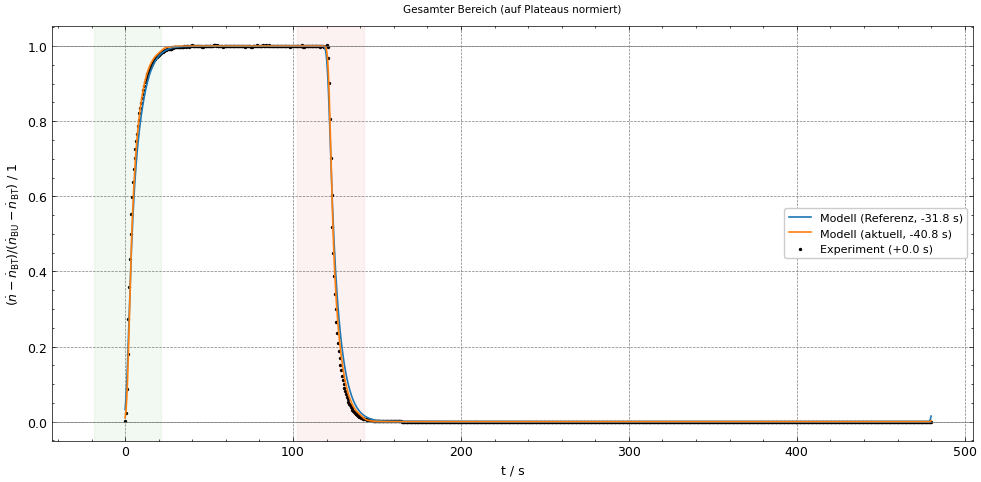

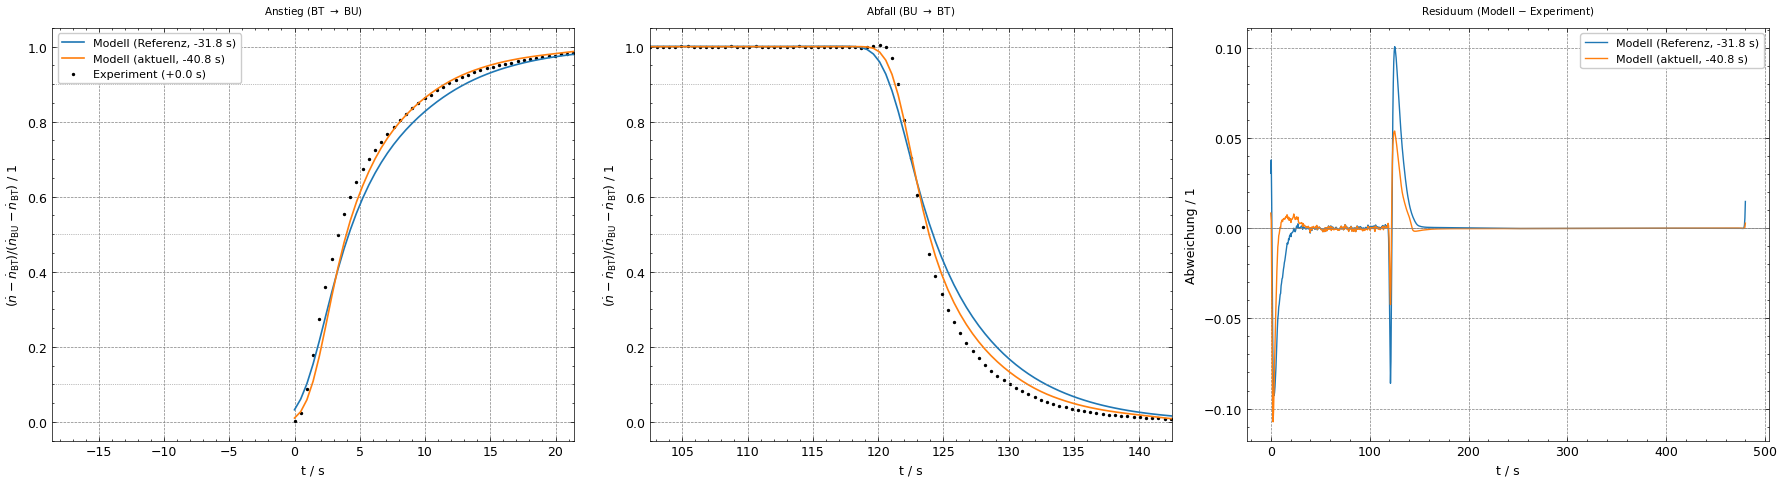

In [12]:
# ================================== ZELLE ==================================
# Vergleich: Referenzmodell / aktuelles Modell / Experiment, Argon.
#
# Alle drei Kurven werden auf ihre stationaeren Plateaus normiert (BT -> 0,
# BU -> 1) und koennen einzeln zeitlich verschoben werden. Bewertet wird
# ausschliesslich auf den Flanken - auf den Plateaus ist das Signal konstant,
# dort ist R2 sinnlos (Nenner -> 0) und RMSE misst nur Rauschen.
# ===========================================================================
Ar = 0
dt_lin = t_lin[1] - t_lin[0]
CYCLE_TIME = 480.0

# ------------------------------------------------------------------ Schalter
# AUTO_OFFSET = True   -> Versatz wird automatisch bestimmt (empfohlen zum Start)
# AUTO_OFFSET = False  -> die drei Werte in OFFSET_MANUAL werden benutzt
AUTO_OFFSET = True

# Manuelle Zeitversaetze in SEKUNDEN. Positiv = Kurve nach rechts (spaeter).
# Auch das EXPERIMENT laesst sich verschieben - noetig z.B. wenn die
# Auswertungsdatei nicht mitgerollt ist und man lieber die Messung auf das
# Modell legt als umgekehrt.
OFFSET_MANUAL = {
    'Experiment': 0.0,
    'Referenz':   0.0,
    'aktuell':    0.0,
}

ZOOM = 20.0          # halbe Breite der Zoomfenster in s
SHOW_ABSOLUTE = True # zusaetzlich die unnormierten Kurven in umol/s zeigen
# ---------------------------------------------------------------------------


def to_grid(t_src, y_src):
    """Bringt ein Modellergebnis auf das Zeitgitter des Experiments (t_lin).

    Modell und Experiment liegen oft auf verschiedenen Rastern (das Modell auf
    dem RTD-Raster dt = 0.25 s, das Experiment auf dt ~ 0.475 s). Ohne
    gemeinsames Raster kann man weder subtrahieren noch Kennzahlen bilden.
    """
    if len(t_src) == len(t_lin) and np.allclose(t_src, t_lin):
        return y_src
    return interpolation_function(t_lin, t_src, y_src)


def estimate_offset(t, curve, reference, cycle_time=CYCLE_TIME):
    """Zeitversatz zwischen zwei periodischen Kurven, zyklisch bestimmt.

    Durchsucht alle moeglichen zyklischen Verschiebungen und nimmt die mit dem
    kleinsten RMSE. np.roll ist hier zulaessig, weil das Signal periodisch ist -
    was hinten herausfaellt, gehoert vorne wieder hinein.

    BEWUSST NICHT ueber scipy.correlate: die Kreuzkorrelation maximiert das
    Ueberlappungsintegral und wird bei rechteckaehnlichen Signalen von den langen
    Plateaus dominiert. Die Flanken, auf die es ankommt, gehen darin unter - im
    Test lag sie 4 s daneben (R2 auf den Flanken 0.87 statt 0.99).

    Returns:
        Versatz in s. Positiv = 'curve' muss nach rechts (spaeter) verschoben
        werden, um auf 'reference' zu passen. Werte > cycle_time/2 werden als
        negativer Versatz zurueckgegeben, weil das leichter zu lesen ist.
    """
    dt = t[1] - t[0]
    errs = [np.sqrt(np.mean((np.roll(curve, s) - reference) ** 2))
            for s in range(curve.size)]
    shift = int(np.argmin(errs)) * dt
    return shift - cycle_time if shift > cycle_time / 2 else shift


def shift_curve(y, offset_s, dt=None):
    """Verschiebt eine periodische Kurve zyklisch um offset_s Sekunden."""
    dt = dt_lin if dt is None else dt
    return np.roll(y, int(round(offset_s / dt)))


# --------------------------------------------- Modelle auf das Experimentgitter
ref_on_grid  = to_grid(t_lin_ref,  n_dot_i_int_ref)
opti_on_grid = to_grid(t_lin_opti, n_dot_i_int_opti)

# --------------------------------------------- Normierung auf die Plateaus
# normalize_steady_state mittelt ueber die MITTLERE Haelfte jeder Halbperiode.
# Nicht y/y.max() verwenden: das Maximum ist ein einzelner Punkt und liegt bei
# ueberschwingenden Kurven 1...3 % ueber dem Plateau. Weil der Ueberschwinger
# kurvenabhaengig ist, entstuende eine Amplitudenabweichung, die es nicht gibt.
exp_ss  = normalize_steady_state(ni_out_cycle[Ar], t_lin)
ref_ss  = normalize_steady_state(ref_on_grid[Ar],  t_lin)
opti_ss = normalize_steady_state(opti_on_grid[Ar], t_lin)

raw = {'Experiment': ni_out_cycle[Ar], 'Referenz': ref_on_grid[Ar], 'aktuell': opti_on_grid[Ar]}
norm = {'Experiment': exp_ss, 'Referenz': ref_ss, 'aktuell': opti_ss}

# --------------------------------------------- Zeitversaetze bestimmen
# Bezug ist immer das (ggf. selbst verschobene) Experiment.
if AUTO_OFFSET:
    exp_ref_curve = shift_curve(exp_ss, OFFSET_MANUAL['Experiment'])
    offset = {'Experiment': OFFSET_MANUAL['Experiment'],
              'Referenz':   estimate_offset(t_lin, ref_ss,  exp_ref_curve),
              'aktuell':    estimate_offset(t_lin, opti_ss, exp_ref_curve)}
    print('Automatisch bestimmte Zeitversaetze:')
else:
    offset = dict(OFFSET_MANUAL)
    print('Manuell gesetzte Zeitversaetze:')
for k, v in offset.items():
    print(f'   {k:12s} {v:+8.2f} s')
print('   (zum Fixieren: AUTO_OFFSET = False und die Werte in OFFSET_MANUAL eintragen)')

shifted = {k: shift_curve(norm[k], offset[k]) for k in norm}
exp_plot = shifted['Experiment']

# Legendentexte
label = {'Referenz':   f'Modell (Referenz, {offset["Referenz"]:+.1f} s)',
         'aktuell':    f'Modell (aktuell, {offset["aktuell"]:+.1f} s)',
         'Experiment': f'Experiment ({offset["Experiment"]:+.1f} s)'}
curves = [(label['Referenz'], shifted['Referenz'], 'tab:blue'),
          (label['aktuell'],  shifted['aktuell'],  'tab:orange')]

# --------------------------------------------- Kennzahlen auf den Flanken
# Die Maske stammt IMMER aus dem Experiment, nie aus der jeweiligen Modellkurve.
# Sonst wird fuer jedes Modell ein anderer Punktesatz bewertet und die Zahlen
# sind untereinander nicht vergleichbar.
mask = flank_mask(exp_plot, t_lin)

print(f'\nKennzahlen auf den Flanken ({mask.sum()} von {t_lin.size} Punkten, normiert):')
print(f'{"":36s} {"R2":>9s} {"RMSE":>9s} {"Anstieg t50/B":>19s} {"Abfall t50/B":>19s}')

def flank_line(lbl, y, with_metrics=True):
    """Eine Zeile der Kennzahlentabelle.

    t50    = Lage der Flanke   -> Fehler in der Verweilzeit tau
    Breite = 10-90-Anstiegzeit -> Fehler in der Dispersion sigma
    Die Trennung ist wichtig: ein zeitversetztes und ein zu breites Modell
    koennen dasselbe R2 haben, brauchen aber verschiedene Korrekturen.
    """
    a, b = flank_stats(t_lin, y, rising=True)
    c, d = flank_stats(t_lin, y, rising=False)
    if with_metrics:
        r2 = 1 - np.sum((exp_plot[mask] - y[mask]) ** 2) / \
                 np.sum((exp_plot[mask] - exp_plot[mask].mean()) ** 2)
        rmse = np.sqrt(np.mean((exp_plot[mask] - y[mask]) ** 2))
        print(f'{lbl:36s} {r2:9.5f} {rmse:9.5f} {a:10.2f}s/{b:5.2f}s {c:11.2f}s/{d:5.2f}s')
    else:
        print(f'{lbl:36s} {"":>9s} {"":>9s} {a:10.2f}s/{b:5.2f}s {c:11.2f}s/{d:5.2f}s')

flank_line(label['Experiment'], exp_plot, with_metrics=False)
for lbl, y, _ in curves:
    flank_line(lbl, y)

# Kontrolle: muss ueberall exakt 1.0000 / 0.0000 sein. Wenn nicht, hat die
# Flankenerkennung in plateau_levels danebengegriffen (z.B. bei sehr
# verrauschten oder driftenden Plateaus) und die Kennzahlen sind unbrauchbar.
print('\nPlateaukontrolle (Soll: BU = 1.0000, BT = 0.0000):')
for k in ['Experiment', 'Referenz', 'aktuell']:
    bu, bt = plateau_levels(shifted[k], t_lin)
    ok = 'ok' if abs(bu - 1) < 1e-4 and abs(bt) < 1e-4 else '<-- PRUEFEN'
    print(f'   {k:12s} BU = {bu:.4f}   BT = {bt:.4f}   {ok}')

# --------------------------------------------- Plots
# Flankenlagen aus dem Experiment ableiten, damit die Zoomfenster automatisch
# an der richtigen Stelle sitzen - auch nachdem verschoben wurde.
g = np.gradient(exp_plot, t_lin)
t_rise, t_fall = t_lin[int(np.argmax(g))], t_lin[int(np.argmin(g))]

def draw(ax, xlim=None, title=''):
    for lbl, y, col in curves:
        ax.plot(t_lin, y, label=lbl, color=col, lw=1.2)
    ax.scatter(t_lin, exp_plot, label=label['Experiment'], color='black', marker='.', s=8)
    if xlim:
        ax.set_xlim(*xlim); ax.set_ylim(-0.05, 1.05)
    ax.set_title(title); ax.set_xlabel('t / s')
    ax.set_ylabel(r'$(\dot n - \dot n_\mathrm{BT})/(\dot n_\mathrm{BU} - \dot n_\mathrm{BT})$ / 1')

fig, ax = plt.subplots(figsize=(10, 5))
draw(ax, title='Gesamter Bereich (auf Plateaus normiert)')
ax.axhline(0, color='gray', lw=0.5)      # Sollwert BT-Plateau
ax.axhline(1, color='gray', lw=0.5)      # Sollwert BU-Plateau
ax.axvspan(t_rise - ZOOM, t_rise + ZOOM, color='tab:green', alpha=0.06)
ax.axvspan(t_fall - ZOOM, t_fall + ZOOM, color='tab:red',   alpha=0.06)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
draw(axes[0], (t_rise - ZOOM, t_rise + ZOOM), 'Anstieg (BT $\\rightarrow$ BU)')
draw(axes[1], (t_fall - ZOOM, t_fall + ZOOM), 'Abfall (BU $\\rightarrow$ BT)')
for ax in axes[:2]:
    for lvl in (0.1, 0.5, 0.9):          # Ablesehilfe fuer die 10-90-Breite
        ax.axhline(lvl, color='gray', lw=0.5, ls=':')

# Residuum: auf den Plateaus flach bei 0 = Normierung sitzt. Ein konstanter
# Versatz dort waere ein Niveaufehler, keine Formabweichung.
for lbl, y, col in curves:
    axes[2].plot(t_lin, y - exp_plot, label=lbl, color=col, lw=1.0)
axes[2].axhline(0, color='gray', lw=0.5)
axes[2].set_title('Residuum (Modell $-$ Experiment)')
axes[2].set_xlabel('t / s'); axes[2].set_ylabel('Abweichung / 1')
axes[0].legend(fontsize=8); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# --------------------------------------------- optional: absolute Darstellung
# Die normierte Ansicht zeigt nur die FORM. Amplitudenfehler (falsche
# Verduennung, Kalibrierdrift) verschwinden darin - deshalb zusaetzlich die
# unnormierten Kurven, damit ein Niveauversatz nicht unbemerkt bleibt.
# if SHOW_ABSOLUTE:
#     fig, ax = plt.subplots(figsize=(10, 5))
#     for k, col in [('Referenz', 'tab:blue'), ('aktuell', 'tab:orange')]:
#         ax.plot(t_lin, shift_curve(raw[k], offset[k]) * 1e6, label=label[k], color=col, lw=1.2)
#     ax.scatter(t_lin, shift_curve(raw['Experiment'], offset['Experiment']) * 1e6,
#                label=label['Experiment'], color='black', marker='.', s=8)
#     ax.set_title('Gesamter Bereich (absolut)')
#     ax.set_xlabel('t / s'); ax.set_ylabel(r'$\dot{n}_\mathrm{Ar}$ / $\mu$mol s$^{-1}$')
#     ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# Bericht plots

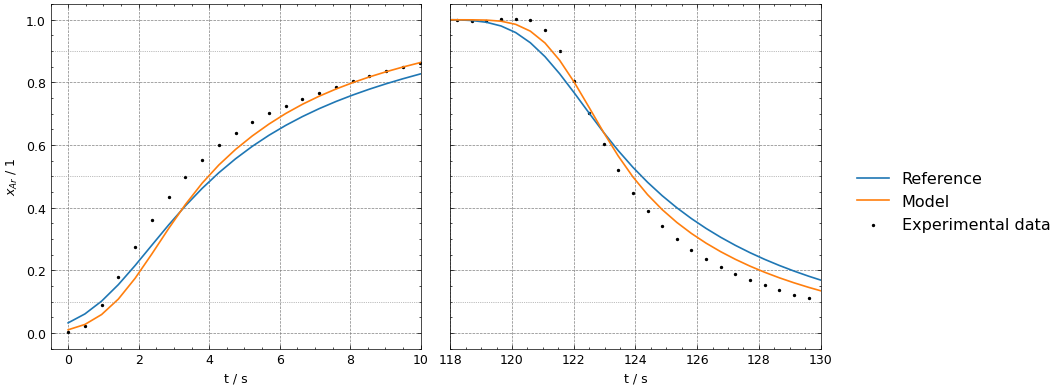

In [13]:

LABELS = {
    'Referenz':   'Reference',
    'aktuell':    'Model',
    'Experiment': 'Experimental data',
}

COLORS = {'Referenz': 'tab:blue', 'aktuell': 'tab:orange', 'Experiment': 'black'}

# --- Achsengrenzen -----------------------------------------------------------
# Jeweils (min, max) in s eintragen, um das Fenster fest zu setzen.
# None  = automatisch: Fenster wird um die aus dem Experiment erkannte Flanke
#         gelegt, halbe Breite = ZOOM_HALF.
XLIM_LINKS   = (-0.5, 10)          # Anstieg,  z.B. (215.0, 255.0)
XLIM_RECHTS  = (118, 130)          # Abfall,   z.B. (455.0, 495.0)
ZOOM_HALF    = ZOOM          # nur wirksam, solange oben None steht

# y-Grenzen: getrennt setzbar. SHARE_Y = True erzwingt dieselbe y-Achse links
# und rechts (fuer den optischen Vergleich der Flankenformen sinnvoll).
YLIM_LINKS   = (-0.05, 1.05)
YLIM_RECHTS  = (-0.05, 1.05)
SHARE_Y      = True          # bei True gilt YLIM_LINKS fuer beide Panels
# -----------------------------------------------------------------------------

X_LABEL     = 't / s'
Y_LABEL     = '$x_{Ar}$ / 1'   # bewusst ohne Formel
HELP_LINES  = True      # waagerechte Hilfslinien bei 0.1 / 0.5 / 0.9
LEGEND_FRAC = 0.78      # Anteil der Figurbreite fuer die Plots, Rest = Legende
# ---------------------------------------------------------------------------

exp_plot = shifted['Experiment']

# Flankenlagen aus dem Experiment: groesster positiver Gradient = Anstieg,
# groesster negativer = Abfall. Wird nur gebraucht, wenn XLIM_* auf None steht.
g = np.gradient(exp_plot, t_lin)
t_rise, t_fall = t_lin[int(np.argmax(g))], t_lin[int(np.argmin(g))]

# Aus Vorgabe oder Automatik die endgueltigen Grenzen bilden.
xlims = [XLIM_LINKS  if XLIM_LINKS  is not None else (t_rise - ZOOM_HALF, t_rise + ZOOM_HALF),
         XLIM_RECHTS if XLIM_RECHTS is not None else (t_fall - ZOOM_HALF, t_fall + ZOOM_HALF)]
ylims = [YLIM_LINKS, YLIM_LINKS if SHARE_Y else YLIM_RECHTS]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=SHARE_Y)

for ax, xlim, ylim in zip(axes, xlims, ylims):
    # Modelle als Linien, Messung als Punktwolke (nicht interpoliert darstellen,
    # damit die tatsaechliche Abtastung des MS sichtbar bleibt).
    for key in ('Referenz', 'aktuell'):
        ax.plot(t_lin, shifted[key], label=LABELS[key], color=COLORS[key], lw=1.2)
    ax.scatter(t_lin, exp_plot, label=LABELS['Experiment'],
               color=COLORS['Experiment'], marker='.', s=8)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel(X_LABEL)

    if HELP_LINES:                      # Ablesehilfe fuer die 10-90-Breite
        for lvl in (0.1, 0.5, 0.9):
            ax.axhline(lvl, color='gray', lw=0.5, ls=':')

axes[0].set_ylabel(Y_LABEL)
if not SHARE_Y:                         # getrennte y-Achsen brauchen beide ein Label
    axes[1].set_ylabel(Y_LABEL)

# Figur-Legende rechts: Handles aus der linken Achse holen, damit jede Kurve
# genau einmal erscheint. subplots_adjust statt tight_layout, weil tight_layout
# die ausserhalb liegende Legende nicht mit einrechnet und sie abschneiden wuerde.
handles, labels_ = axes[0].get_legend_handles_labels()
fig.subplots_adjust(left=0.08, right=LEGEND_FRAC, bottom=0.15, top=0.97,
                    wspace=0.08 if SHARE_Y else 0.25)
fig.legend(handles, labels_, loc='center left',
           bbox_to_anchor=(LEGEND_FRAC + 0.02, 0.5), fontsize=11.5, frameon=False)

plt.show()

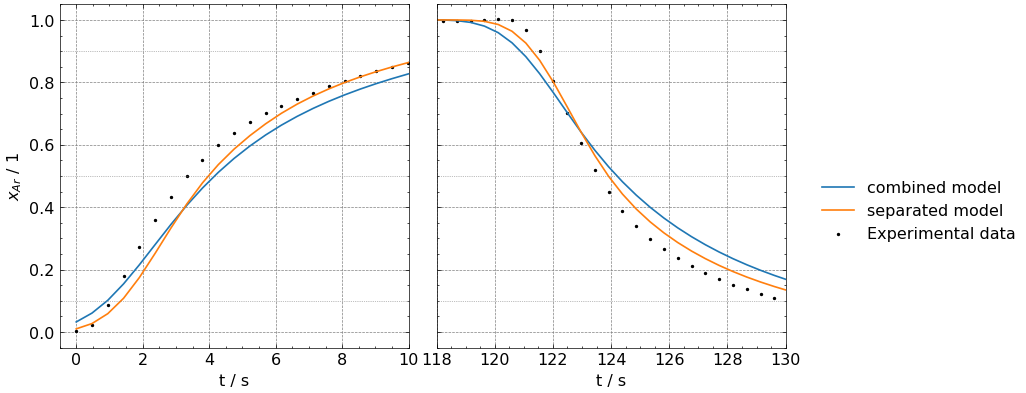

In [14]:
LABELS = {
    'Referenz':   'combined model',
    'aktuell':    'separated model',
    'Experiment': 'Experimental data',
}

COLORS = {'Referenz': 'tab:blue', 'aktuell': 'tab:orange', 'Experiment': 'black'}

# --- Schriftgroessen ---------------------------------------------------------
FONT_LABEL  = 11.5     # Achsentitel
FONT_TICK   = 11.5     # Zahlen an den Achsen
FONT_LEGEND = 11.5     # Legende
# -----------------------------------------------------------------------------

# --- Achsengrenzen -----------------------------------------------------------
XLIM_LINKS   = (-0.5, 10)
XLIM_RECHTS  = (118, 130)
ZOOM_HALF    = ZOOM          # nur wirksam, solange oben None steht

YLIM_LINKS   = (-0.05, 1.05)
YLIM_RECHTS  = (-0.05, 1.05)
SHARE_Y      = True
# -----------------------------------------------------------------------------

X_LABEL     = 't / s'
Y_LABEL     = '$x_{Ar}$ / 1'
HELP_LINES  = True
LEGEND_FRAC = 0.76      # etwas kleiner, damit die groessere Legende Platz hat
# ---------------------------------------------------------------------------

exp_plot = shifted['Experiment']

g = np.gradient(exp_plot, t_lin)
t_rise, t_fall = t_lin[int(np.argmax(g))], t_lin[int(np.argmin(g))]

xlims = [XLIM_LINKS  if XLIM_LINKS  is not None else (t_rise - ZOOM_HALF, t_rise + ZOOM_HALF),
         XLIM_RECHTS if XLIM_RECHTS is not None else (t_fall - ZOOM_HALF, t_fall + ZOOM_HALF)]
ylims = [YLIM_LINKS, YLIM_LINKS if SHARE_Y else YLIM_RECHTS]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=SHARE_Y)

for ax, xlim, ylim in zip(axes, xlims, ylims):
    for key in ('Referenz', 'aktuell'):
        ax.plot(t_lin, shifted[key], label=LABELS[key], color=COLORS[key], lw=1.2)
    ax.scatter(t_lin, exp_plot, label=LABELS['Experiment'],
               color=COLORS['Experiment'], marker='.', s=8)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel(X_LABEL, fontsize=FONT_LABEL)
    ax.tick_params(axis='both', labelsize=FONT_TICK)

    if HELP_LINES:
        for lvl in (0.1, 0.5, 0.9):
            ax.axhline(lvl, color='gray', lw=0.5, ls=':')

axes[0].set_ylabel(Y_LABEL, fontsize=FONT_LABEL)
if not SHARE_Y:
    axes[1].set_ylabel(Y_LABEL, fontsize=FONT_LABEL)

handles, labels_ = axes[0].get_legend_handles_labels()
fig.subplots_adjust(left=0.10, right=LEGEND_FRAC, bottom=0.19, top=0.97,
                    wspace=0.08 if SHARE_Y else 0.28)
fig.legend(handles, labels_, loc='center left',
           bbox_to_anchor=(LEGEND_FRAC + 0.02, 0.5), fontsize=FONT_LEGEND, frameon=False)

plt.show()